In [50]:
print("Electricity Consumption Analysis and Forecasting")
print("My first Machine Learning Project")

Electricity Consumption Analysis and Forecasting
My first Machine Learning Project


In [51]:
import urllib.request
import zipfile
import os

# Download dataset
url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

urllib.request.urlretrieve(url, "electricity_data.zip")

# Extract ZIP file
with zipfile.ZipFile("electricity_data.zip", "r") as zip_ref:
    zip_ref.extractall("electricity_data")

print("Dataset downloaded successfully!")

# Display extracted files
print(os.listdir("electricity_data"))

Dataset downloaded successfully!
['household_power_consumption.txt']


In [52]:
import pandas as pd

file_path = "electricity_data/household_power_consumption.txt"

df = pd.read_csv(file_path, sep=";", na_values=["?"])

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [53]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [54]:
print(df.shape)

(2075259, 9)


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


In [56]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979


In [57]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [58]:
# Combine Date and Time columns
df['Datetime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    format='%d/%m/%Y %H:%M:%S'
)

print("Date and time converted successfully!")
print(df[['Datetime']].head())

Date and time converted successfully!
             Datetime
0 2006-12-16 17:24:00
1 2006-12-16 17:25:00
2 2006-12-16 17:26:00
3 2006-12-16 17:27:00
4 2006-12-16 17:28:00


In [59]:
# Select electricity columns
numeric_cols = df.columns[2:9]

# Convert columns into numeric format
df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric, errors='coerce'
)

print("Numeric conversion completed!")

Numeric conversion completed!


In [60]:
print("Missing values in dataset:")
print(df.isnull().sum())

Missing values in dataset:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
Datetime                     0
dtype: int64


In [61]:
# Set Datetime as index
df = df.set_index('Datetime')

# Sort records by time
df = df.sort_index()

# Fill missing values using interpolation
df[numeric_cols] = df[numeric_cols].interpolate(
    method='time'
).ffill().bfill()

print("Missing values handled successfully!")
print("Remaining missing values:", df.isnull().sum().sum())

Missing values handled successfully!
Remaining missing values: 0


In [62]:
print("Final dataset shape:", df.shape)

print("\nFirst 5 cleaned records:")
print(df.head())

Final dataset shape: (2075259, 9)

First 5 cleaned records:
                           Date      Time  Global_active_power  \
Datetime                                                         
2006-12-16 17:24:00  16/12/2006  17:24:00                4.216   
2006-12-16 17:25:00  16/12/2006  17:25:00                5.360   
2006-12-16 17:26:00  16/12/2006  17:26:00                5.374   
2006-12-16 17:27:00  16/12/2006  17:27:00                5.388   
2006-12-16 17:28:00  16/12/2006  17:28:00                3.666   

                     Global_reactive_power  Voltage  Global_intensity  \
Datetime                                                                
2006-12-16 17:24:00                  0.418   234.84              18.4   
2006-12-16 17:25:00                  0.436   233.63              23.0   
2006-12-16 17:26:00                  0.498   233.29              23.0   
2006-12-16 17:27:00                  0.502   233.74              23.0   
2006-12-16 17:28:00                  0.

In [63]:
# Calculate daily electricity consumption
daily_data = df['Global_active_power'].resample('D').sum() / 60

# Convert into DataFrame
daily_data = daily_data.to_frame(name='Daily_Consumption')

print(daily_data.head())

            Daily_Consumption
Datetime                     
2006-12-16          20.152933
2006-12-17          56.507667
2006-12-18          36.730433
2006-12-19          27.769900
2006-12-20          37.095800


In [64]:
monthly_data = daily_data.resample('ME').sum()

print(monthly_data.head())

            Daily_Consumption
Datetime                     
2006-12-31         697.113433
2007-01-31        1150.288267
2007-02-28         941.613800
2007-03-31         981.045350
2007-04-30         608.819867


In [65]:
average_usage = daily_data['Daily_Consumption'].mean()

print("Average Daily Consumption:", round(average_usage, 2), "kWh")

Average Daily Consumption: 26.15 kWh


In [66]:
highest_day = daily_data['Daily_Consumption'].idxmax()
lowest_day = daily_data['Daily_Consumption'].idxmin()

print("Highest Consumption Day:", highest_day.date())
print("Highest Usage:", round(daily_data.loc[highest_day, 'Daily_Consumption'], 2), "kWh")

print("\nLowest Consumption Day:", lowest_day.date())
print("Lowest Usage:", round(daily_data.loc[lowest_day, 'Daily_Consumption'], 2), "kWh")

Highest Consumption Day: 2006-12-23
Highest Usage: 79.56 kWh

Lowest Consumption Day: 2008-08-25
Lowest Usage: 4.17 kWh


In [67]:
daily_data['Day'] = daily_data.index.day_name()

weekday_usage = daily_data.groupby('Day')['Daily_Consumption'].mean()

print(weekday_usage)

Day
Friday       24.995152
Monday       24.041983
Saturday     29.503411
Sunday       29.113896
Thursday     23.569725
Tuesday      25.794473
Wednesday    26.040617
Name: Daily_Consumption, dtype: float64


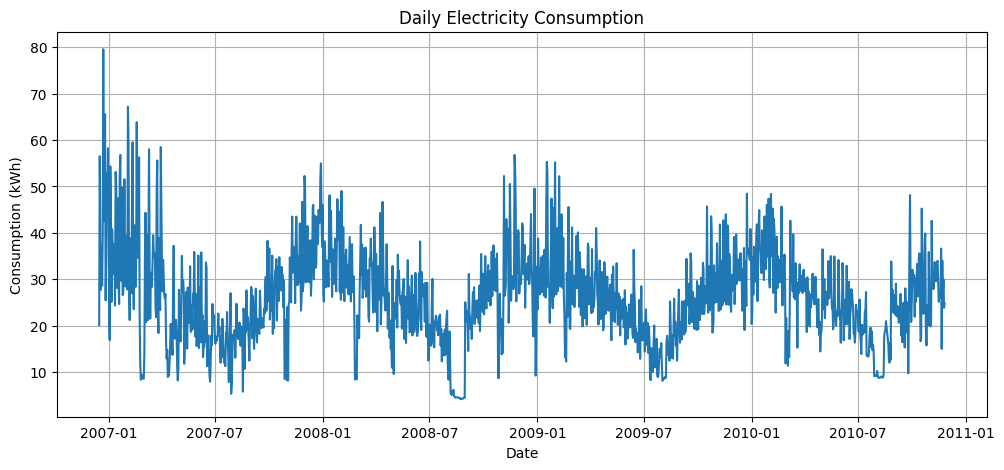

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(daily_data.index,
         daily_data['Daily_Consumption'])

plt.title("Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")

plt.grid(True)
plt.show()

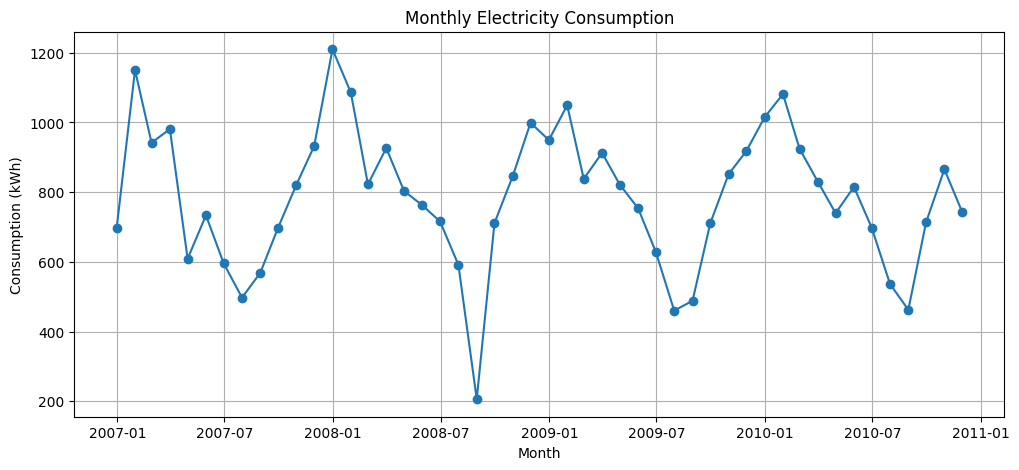

In [69]:
plt.figure(figsize=(12,5))

plt.plot(monthly_data.index,
         monthly_data['Daily_Consumption'],
         marker='o')

plt.title("Monthly Electricity Consumption")
plt.xlabel("Month")
plt.ylabel("Consumption (kWh)")

plt.grid(True)
plt.show()

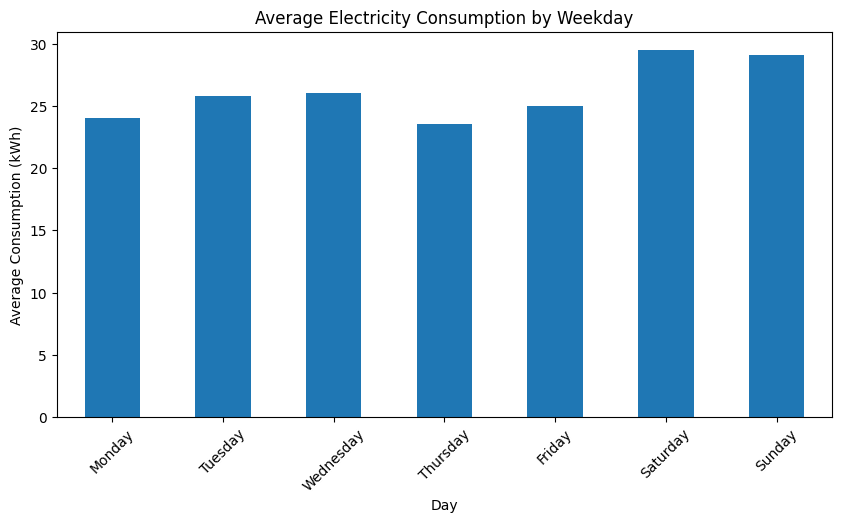

In [70]:
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_usage = weekday_usage.reindex(weekday_order)

plt.figure(figsize=(10,5))

weekday_usage.plot(kind='bar')

plt.title("Average Electricity Consumption by Weekday")
plt.xlabel("Day")
plt.ylabel("Average Consumption (kWh)")

plt.xticks(rotation=45)
plt.show()

In [71]:
# Create a copy of daily consumption data
ml_data = daily_data[['Daily_Consumption']].copy()

# Create date-based features
ml_data['Day'] = ml_data.index.day
ml_data['Month'] = ml_data.index.month
ml_data['Year'] = ml_data.index.year
ml_data['Weekday'] = ml_data.index.dayofweek
ml_data['DayOfYear'] = ml_data.index.dayofyear

# Display dataset
print(ml_data.head())

            Daily_Consumption  Day  Month  Year  Weekday  DayOfYear
Datetime                                                           
2006-12-16          20.152933   16     12  2006        5        350
2006-12-17          56.507667   17     12  2006        6        351
2006-12-18          36.730433   18     12  2006        0        352
2006-12-19          27.769900   19     12  2006        1        353
2006-12-20          37.095800   20     12  2006        2        354


In [72]:
X = ml_data[['Day', 'Month', 'Year', 'Weekday', 'DayOfYear']]

y = ml_data['Daily_Consumption']

print("Input features:", X.shape)
print("Target values:", y.shape)

Input features: (1442, 5)
Target values: (1442,)


In [73]:
# Add previous consumption features
ml_data['Previous_Day'] = ml_data['Daily_Consumption'].shift(1)

ml_data['Previous_Week'] = ml_data['Daily_Consumption'].shift(7)

ml_data['Weekly_Average'] = (
    ml_data['Daily_Consumption'].shift(1).rolling(7).mean()
)

# Remove rows with missing lag values
ml_data = ml_data.dropna()

# Select input and output
X = ml_data[['Day', 'Month', 'Year', 'Weekday',
             'DayOfYear', 'Previous_Day',
             'Previous_Week', 'Weekly_Average']]

y = ml_data['Daily_Consumption']

print("Features prepared successfully!")
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Features prepared successfully!
Input shape: (1435, 8)
Output shape: (1435,)


In [74]:
split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1148
Testing records: 287


In [75]:
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [76]:
from sklearn.ensemble import RandomForestRegressor

# Create model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [77]:
# Linear Regression predictions
lr_predictions = lr_model.predict(X_test)

# Random Forest predictions
rf_predictions = rf_model.predict(X_test)

print("Both models generated predictions successfully!")

Both models generated predictions successfully!


In [78]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Linear Regression evaluation
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

# Random Forest evaluation
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("LINEAR REGRESSION")
print("MAE:", round(lr_mae, 2))
print("RMSE:", round(lr_rmse, 2))
print("R2 Score:", round(lr_r2, 3))

print("\nRANDOM FOREST")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 3))

LINEAR REGRESSION
MAE: 4.31
RMSE: 5.96
R2 Score: 0.366

RANDOM FOREST
MAE: 4.21
RMSE: 5.71
R2 Score: 0.417


In [79]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

print(results)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  4.306241  5.957242  0.366081
1      Random Forest  4.206312  5.714653  0.416659


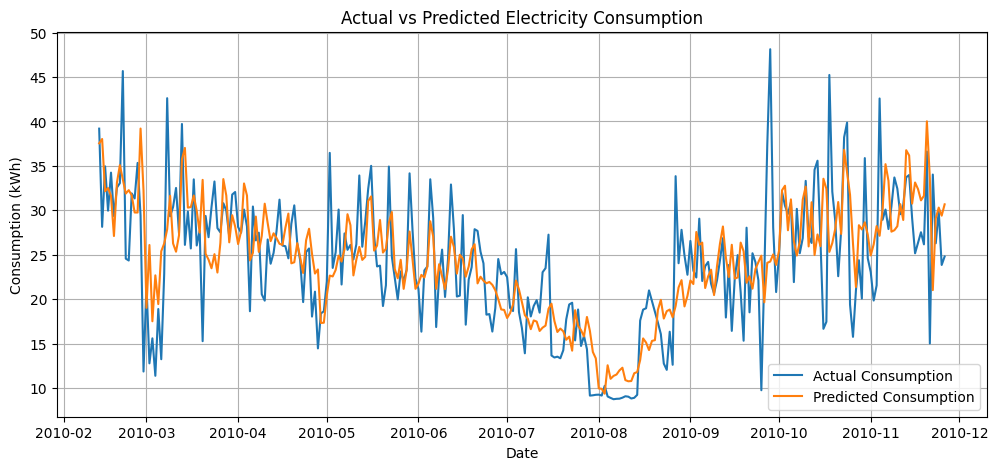

Selected model: Random Forest


In [80]:
# Select model with lower MAE
if rf_mae < lr_mae:
    best_predictions = rf_predictions
    best_name = "Random Forest"
else:
    best_predictions = lr_predictions
    best_name = "Linear Regression"

plt.figure(figsize=(12,5))

plt.plot(y_test.index, y_test.values,
         label='Actual Consumption')

plt.plot(y_test.index, best_predictions,
         label='Predicted Consumption')

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")

plt.legend()
plt.grid(True)
plt.show()

print("Selected model:", best_name)

In [81]:
if rf_mae < lr_mae:
    best_model = rf_model
    best_name = "Random Forest"
else:
    best_model = lr_model
    best_name = "Linear Regression"

print("Best Model:", best_name)

Best Model: Random Forest


In [82]:
# Store historical daily consumption
history = daily_data['Daily_Consumption'].tolist()

# Get the last available date
last_date = daily_data.index[-1]

print("Last Available Date:", last_date.date())
print("Historical records:", len(history))

Last Available Date: 2010-11-26
Historical records: 1442


In [83]:
import numpy as np

future_predictions = []
future_dates = []

# Predict next 7 days
for i in range(7):

    next_date = last_date + pd.Timedelta(days=i+1)

    # Prepare input features
    features = pd.DataFrame([{
        'Day': next_date.day,
        'Month': next_date.month,
        'Year': next_date.year,
        'Weekday': next_date.dayofweek,
        'DayOfYear': next_date.dayofyear,
        'Previous_Day': history[-1],
        'Previous_Week': history[-7],
        'Weekly_Average': np.mean(history[-7:])
    }])

    # Predict consumption
    prediction = best_model.predict(features)[0]

    # Electricity consumption cannot be negative
    prediction = max(0, prediction)

    future_predictions.append(prediction)
    future_dates.append(next_date)

    # Add prediction for the next forecast
    history.append(prediction)

print("7-Day Forecast Generated Successfully!")

7-Day Forecast Generated Successfully!


In [84]:
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Consumption_kWh': future_predictions
})

print(forecast_df.round(2))

        Date  Predicted_Consumption_kWh
0 2010-11-27                      37.26
1 2010-11-28                      36.20
2 2010-11-29                      29.04
3 2010-11-30                      28.42
4 2010-12-01                      31.44
5 2010-12-02                      27.77
6 2010-12-03                      27.85


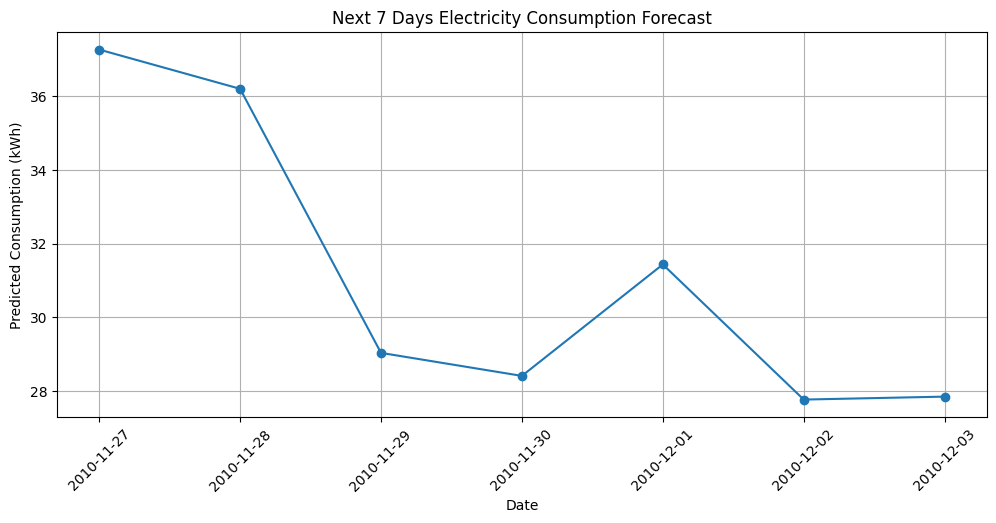

In [85]:
plt.figure(figsize=(12, 5))

plt.plot(
    forecast_df['Date'],
    forecast_df['Predicted_Consumption_kWh'],
    marker='o'
)

plt.title("Next 7 Days Electricity Consumption Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Consumption (kWh)")

plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [86]:
total_forecast = forecast_df['Predicted_Consumption_kWh'].sum()

average_forecast = forecast_df['Predicted_Consumption_kWh'].mean()

print("Total 7-Day Consumption:", round(total_forecast, 2), "kWh")
print("Average Daily Consumption:", round(average_forecast, 2), "kWh")

Total 7-Day Consumption: 217.98 kWh
Average Daily Consumption: 31.14 kWh


In [87]:
rate_per_unit = 8

estimated_bill = total_forecast * rate_per_unit

print("Electricity Rate: ₹", rate_per_unit, "per unit")
print("Estimated 7-Day Electricity Bill: ₹", round(estimated_bill, 2))

Electricity Rate: ₹ 8 per unit
Estimated 7-Day Electricity Bill: ₹ 1743.84


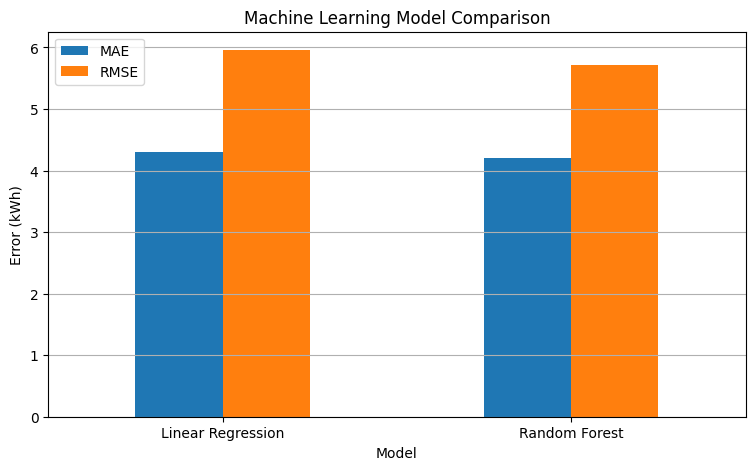

In [88]:
import matplotlib.pyplot as plt

results.set_index('Model')[['MAE', 'RMSE']].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Error (kWh)")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

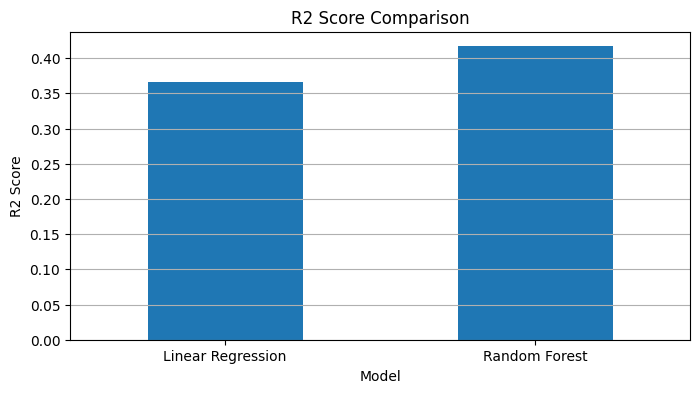

In [89]:
results.plot(
    x='Model',
    y='R2 Score',
    kind='bar',
    legend=False,
    figsize=(8, 4)
)

plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [90]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

print(importance)

          Feature  Importance
7  Weekly_Average    0.452565
5    Previous_Day    0.195362
4       DayOfYear    0.096745
6   Previous_Week    0.087380
3         Weekday    0.075529
0             Day    0.049120
2            Year    0.029655
1           Month    0.013644


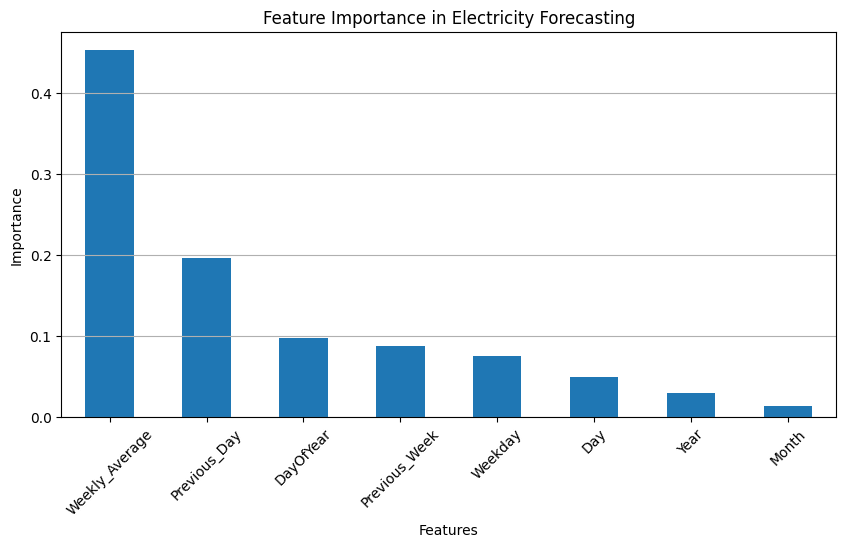

In [91]:
importance.plot(
    x='Feature',
    y='Importance',
    kind='bar',
    figsize=(10, 5),
    legend=False
)

plt.title("Feature Importance in Electricity Forecasting")
plt.ylabel("Importance")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [92]:
import joblib

joblib.dump(best_model, 'electricity_model.pkl')

print("Machine learning model saved successfully!")

Machine learning model saved successfully!


In [93]:
loaded_model = joblib.load('electricity_model.pkl')

test_prediction = loaded_model.predict(X_test.iloc[:5])

print("Predictions using saved model:")
print(test_prediction)

Predictions using saved model:
[37.54134867 38.02710936 32.14984432 32.5064207  31.63403775]


In [94]:
forecast_df.to_csv(
    'electricity_forecast.csv',
    index=False
)

print("Forecast CSV file created successfully!")

Forecast CSV file created successfully!


In [95]:
from google.colab import files

files.download('electricity_forecast.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [96]:
files.download('electricity_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [97]:
print("ELECTRICITY CONSUMPTION ANALYSIS AND FORECASTING")
print("-----------------------------------------------")

print("Best Model:", best_name)

print("Average Daily Consumption:",
      round(average_usage, 2), "kWh")

print("7-Day Predicted Consumption:",
      round(total_forecast, 2), "kWh")

print("Estimated 7-Day Electricity Bill: ₹",
      round(estimated_bill, 2))


ELECTRICITY CONSUMPTION ANALYSIS AND FORECASTING
-----------------------------------------------
Best Model: Random Forest
Average Daily Consumption: 26.15 kWh
7-Day Predicted Consumption: 217.98 kWh
Estimated 7-Day Electricity Bill: ₹ 1743.84
